<a href="https://colab.research.google.com/github/thuongle825/Midterm-Project-Econ_3916_Midterm/blob/main/midterm_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 Midterm Project — Econometric Foundation

**ECON 3916 · Applied Data Analytics** · Topics 1-14 · 100 points · your role: Independent analyst

This is the **starter**: the structure of the project in rubric order. Fill the empty cells and keep every heading so the grader finds each section. The brief on Canvas has the full text of every section and the rubric. The grader reruns this notebook from the top, so every number, table and figure in your report must come from a cell here.

**🛑 This project is entirely NO AI.** Not phases one to three — all of it. No AI for the code, the analysis, the writing, or the editing. This is the one assessment in the course that establishes you can do the work unaided, and it is the one you will draw on when an interviewer asks what you built. Everything you have practised with a co-pilot, you do here alone.

## Start here

Work top to bottom. What each part of this notebook is for:

1. **Data provenance**: where the file came from. It feeds Section 1 and your README.
2. **Section 1**: load the data into a DataFrame called `df`, then run the *Section 1 self-check* cell and answer the questions under it. Do this before the **Mon 2 Nov** checkpoint.
3. **Section 2**: figures, each with a caption that states a finding.
4. **Section 3**: the OLS model, with a draft committed by **Fri 6 Nov**.
5. **Section 4**: diagnostics, only after Topic 14.
6. **Section 5**: words only.
7. **Numbers my report quotes**: last. Every number in the report must be printed there.

The brief's *Six checks before you post* list the problems that came up most often in Checkpoint 1. Read them before you settle on your controls.

## Setup

Imports only. Add any others you need here, at the top.

In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.iolib.summary2 import summary_col
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
import os

## Data provenance

Fill these in when you download the data. They feed Section 1 and your README.

In [71]:
SOURCE_URL = {
    "flfp":  "https://data.worldbank.org/indicator/SL.TLF.CACT.FE.ZS",
    "elec":  "https://data.worldbank.org/indicator/EG.ELC.ACCS.ZS",
    "gdp":   "https://data.worldbank.org/indicator/NY.GDP.PCAP.PP.KD",
    "urban": "https://data.worldbank.org/indicator/SP.URB.TOTL.IN.ZS",
}
DOWNLOAD_DATE = "2026-10-31"    # YYYY-MM-DD
FILE_NAME = {
    "flfp":  "data/API_SL.TLF.CACT.FE.ZS_DS2_en_csv_v2_3762.csv",
    "elec":  "data/API_EG.ELC.ACCS.ZS_DS2_en_csv_v2_987.csv",
    "gdp":   "data/API_NY.GDP.PCAP.PP.KD_DS2_en_csv_v2_1629.csv",
    "urban": "data/API_SP.URB.TOTL.IN.ZS_DS2_en_csv_v2_3467.csv",
}

**Who collected it, for what purpose, what is missing and why?**


All four variables come from the World Bank's World Development Indicators, but the World BAnk gets most of the data from other organizations instead of collecting it itself. Each organization collected the data for a different purpose.

Female labor force participation comes from the ILO's modeled estimates. The ILO uses national labor force surbeys and a model to fill in missing years countires. The purpose is to make the data comparable across countries and years so labor markets can be tracked worldwide. This is important because some countries do not conduct surveys as oftern, meaning some of the values are estimate rather than actual survey results.

Electricity access comes from household surveys and national data compiled by the World Bank. The purpose is to track how many people have access to electricity and monitor progress over time. Values between surveys are also estimated, so not every year is based on directly collected data,

GDP per capita in constant PPP international dollars comes from national accounts and is adjusted using price comparisions across countries through the World Bank's international Comparison Program. The purpose is to compare living standards between countries while accounting for differencees in prices. This is why I use constatn PPP dollars insteand of current dollars.

Urban population share comes from the UN Population Division and is mainly based on national censuses. The purpose is to track how much of each country's population lives in urban areas. However, each country has its own definition of what counts as "urban,", which makes this variable less comparable across countries. Since I use country dummies, this matters less because the model compares each country to itslef over time.

Missing data is mostly concentrated in entire countries rather than scattered years. Female labor force participation missing for small territories like Monaco, Bermuda, and Tuvalu, while GDP per capita is missing for countries affected by conflict or closed economies, such as Venezula, Yemen and North Korea. Electricity access is also missing for some countries, while urban population share has no missing values. After dropping incomplete rows, my final sample includes 4,389 country years from 177 countries.

The missingness is no MCAR because it is related to country characteristics. For small territories, missingness is likely MAR because their size and political status do not have an obvious connection to women's employment. However, for counttires affected by conflict and economic collapse, MNAR is possible because these factors can also affect electricity access and labor force participation. This means my result may not apply to countries with the least stable economies and labor markets.

## Section 1: The Question and the Data (20 pts)

State the question in one sentence, and say why it matters and to whom. Describe the data as a product of measurement decisions, name the missingness mechanism (MCAR, MAR or MNAR) and defend the label. Build a summary-statistics table a reader can read without asking you a question.

In [72]:
META_FILE = "data/Metadata_Country_API_SL.TLF.CACT.FE.ZS_DS2_en_csv_v2_3762.csv"

meta = pd.read_csv(META_FILE)
countries = meta.loc[meta["Region"].notna(), "Country Code"]

long_files = []
for var, path in FILE_NAME.items():
  wide = pd.read_csv(path, skiprows=4)
  wide = wide[wide["Country Code"].isin(countries)]
  years = [c for c in wide.columns if c.isdigit() and 2000 <= int(c) <= 2024]
  long = wide.melt(id_vars=["Country Name", "Country Code"], value_vars = years,
                   var_name = "year", value_name = var)
  long["year"] = long["year"].astype(int)
  long_files.append(long)

df = long_files[0]
for long in long_files[1:]:
  df = df.merge(long, on=["Country Name", "Country Code", "year"], how = "outer")

df = df.rename(columns={"Country Name": "country", "Country Code": "cc"})
df["log_gdp"] = np.log(df["gdp"])

est = df.dropna(subset=["flfp", "elec", "log_gdp", "urban"]).copy()

print("Full panel:", df.shape, "|", df["cc"].nunique(), "countries |", df["year"].min(), "-", df["year"].max())
print("Estimation sample:", len(est), "rows from", est["cc"].nunique(), "countries")

paper = {
    "rows_full": len(df),
    "countries_full": df["cc"].nunique(),
    "rows_est": len(est),
    "countries_est": est["cc"].nunique(),
    **{f"missing_{v}": int(df[v].isna().sum()) for v in ["flfp", "elec", "gdp", "urban"]},
}

Full panel: (5425, 8) | 217 countries | 2000 - 2024
Estimation sample: 4389 rows from 177 countries


In [73]:
# Section 1 self-check: run once your data is loaded into a DataFrame called df.
# It prints what Section 1 has to report. It doesn't judge your choices: answer the questions below.
UNIT = "country-year"        # one row is one what? e.g. "county" or "country-year"
OUTCOME = "flfp"     # your dependent variable's column name
MAIN_X = "elec"      # your main explanatory variable's column name
CONTROLS = ["log_gdp", "urban", "cc", "year"]    # every other column in your model

if "df" in globals():
    print(f"Rows: {len(df):,}   Columns: {df.shape[1]}   One row is: {UNIT or '(fill in UNIT)'}")
    cols = [c for c in [OUTCOME, MAIN_X, *CONTROLS] if c]
    absent = [c for c in cols if c not in df.columns]
    if absent:
        print("Not in df:", absent)
    present = [c for c in cols if c in df.columns]
    if present:
        print("\nMissing values per column:")
        print(df[present].isna().sum().to_string())
    if OUTCOME in df.columns and pd.api.types.is_numeric_dtype(df[OUTCOME]):
        print(f"\nSkew of {OUTCOME}: {df[OUTCOME].skew():.2f} (above about 1, consider a log)")
else:
    print("Load your data into a DataFrame called df first, then run this cell.")

Rows: 5,425   Columns: 8   One row is: country-year

Missing values per column:
flfp       759
elec        75
log_gdp    509
urban        0
cc           0
year         0

Skew of flfp: -0.46 (above about 1, consider a log)


In [74]:
labels = {
    "flfp": "Female labor force participation (% of women 15+)",
    "elec": "Access to electricity (% of population)",
    "gdp": "GDP per capita (constant PPP international $)",
    "log_gdp": "Log GDP per capita",
    "urban": "Urban population (% of population)"
}

summary = (est[list(labels)].describe().T
           [["count", "mean", "std", "min", "50%", "max"]]
           .rename(columns={"count": "N", "mean": "Mean", "std": "Std. dev.",
                            "min": "Min", "50%": "Median", "max": "Max"})
           .rename (index=labels))
summary["N"] = summary["N"].astype(int)
summary = summary.round(2)

print(f"Summary statistics, estimation sample: {len(est):,} country-years, "
      f"{est['cc']. nunique()} countries, 2000-2024")
print(summary.to_string())

os. makedirs("outputs", exist_ok = True)
summary.to_csv("outputs/table1_summary_stats.csv")

paper["skew_flfp"] = round(est["flfp"].skew(), 2)
paper["skew_gdp"] = round(est["gdp"].skew(), 2)
paper["skew_log_gdp"] = round(est["log_gdp"].skew(), 2)


Summary statistics, estimation sample: 4,389 country-years, 177 countries, 2000-2024
                                                      N      Mean  Std. dev.     Min    Median        Max
Female labor force participation (% of women 15+)  4389     50.29      15.40    5.12     52.21      87.82
Access to electricity (% of population)            4389     79.69      29.81    1.30     98.70     100.00
GDP per capita (constant PPP international $)      4389  22931.28   24948.59  702.85  13479.70  174569.52
Log GDP per capita                                 4389      9.43       1.18    6.56      9.51      12.07
Urban population (% of population)                 4389     57.90      22.95    8.04     59.28     100.00


**Answer before you go on.**

1. For each control: does your main explanatory variable change it? If yes, it is on the path from X to Y. Drop it, or run with and without and say what each version measures.
2. Are all your variables in the same units and for the same years?
3. If your question is about a policy, where is the period before it?


1. Log GDP per capita: Yes, my main explanatory variable does change it. Electricity can increase income by making businesses and workers more productive. However, GDP is also a confounder because richer countries tend to have more electricity and different female employment rates. I run the model with and without GDP to see how much of the electricity association may work through income.

Urban population: No, the main direction is from urbanization to electricity because cities are usually electrified first. Electricity may encourage some people to move to cities, but this effect is likely small, so I keep urban share as a control.

Country and year dummies: No, electricity cannot change which country or year an observation belongs to. Country dummies control for differences between countries over time, while year dummies control for changes that affect all countries in the same year.

2. All variables are measured at the country year level from 2000 - 2024.
Female participation,electricity access and urban share are measured as percentages. GDP per capita is measured in constant PPP international dollars, and I use its log because the data is skewed.

3. My question is not about a specific policy, so there is no single start date or before period. Electricity access increases gradually and at different times across countries. With country dummies, the model compares each country with itself over 2000 - 2024, using changes in electricity access over time.

## Section 2: Descriptive Evidence (20 pts)

Show the reader the data before any model. At least two figures, each with a caption that states its finding, not its variables. Chapter 3's standards for axes. If the outcome is skewed, show it and say what you will do about it.

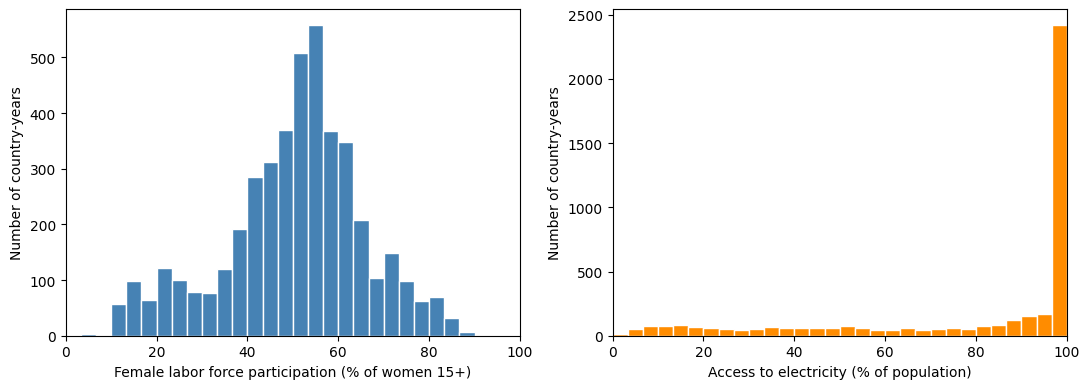

Skew of female participation: -0.42
Share of country-years with electricity access of 99% or more: 48.8 %


In [75]:
# Figure 1
fig, axes = plt.subplots(1, 2, figsize= (11, 4))

axes[0].hist(est["flfp"], bins = 30, range = (0, 100), color = "steelblue", edgecolor = "white")
axes[0].set_xlabel("Female labor force participation (% of women 15+)")
axes[0].set_ylabel("Number of country-years")
axes[0].set_xlim (0, 100)

axes[1].hist(est["elec"], bins = 30, range = (0, 100), color = "darkorange", edgecolor = "white")
axes[1].set_xlabel("Access to electricity (% of population)")
axes[1].set_ylabel("Number of country-years")
axes[1].set_xlim(0, 100)

plt.tight_layout()
plt.savefig("outputs/fig1_distributions.png", dpi = 200)
plt.show()

paper["share_elec_99plus"] = round((est["elec"] >= 99).mean() * 100, 1)
print("Skew of female participation:", paper["skew_flfp"])
print("Share of country-years with electricity access of 99% or more:", paper["share_elec_99plus"], "%")

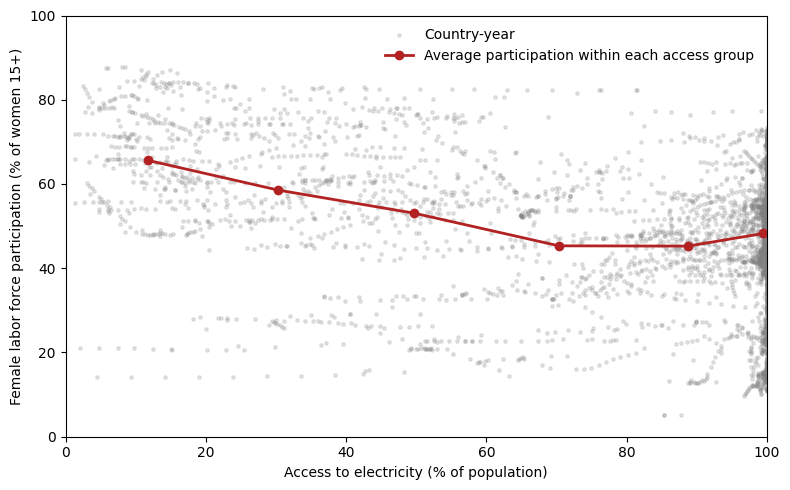

                elec_mid  flfp_mean     n
elec_group                               
(0.0, 20.0]         11.8       65.6   360
(20.0, 40.0]        30.3       58.6   332
(40.0, 60.0]        49.7       53.1   356
(60.0, 80.0]        70.3       45.3   319
(80.0, 95.0]        88.7       45.3   507
(95.0, 100.01]      99.5       48.3  2515


In [76]:
# Figure 2
bins = [0, 20, 40, 60, 80, 95, 100.01]
est["elec_group"] = pd.cut(est["elec"], bins)
group_means = est.groupby("elec_group", observed = True) .agg(
    elec_mid=("elec", "mean"), flfp_mean=("flfp", "mean"), n=("flfp", "size"))

fig, ax = plt.subplots(figsize= (8, 5))
ax.scatter(est["elec"], est["flfp"], s = 6, alpha = 0.2, color = "gray", label = "Country-year")
ax.plot(group_means["elec_mid"], group_means["flfp_mean"], "o-", color = "firebrick",
        linewidth = 2, label = "Average participation within each access group")
ax.set_xlabel("Access to electricity (% of population)")
ax.set_ylabel("Female labor force participation (% of women 15+)")
ax.set_xlim(0, 100)
ax. set_ylim (0, 100)
ax.legend(frameon = False)
plt.tight_layout()
plt.savefig("outputs/fig2_flfp_vs_electricity.png", dpi=200)
plt.show()

print (group_means.round(1).to_string())
est = est.drop(columns="elec_group")

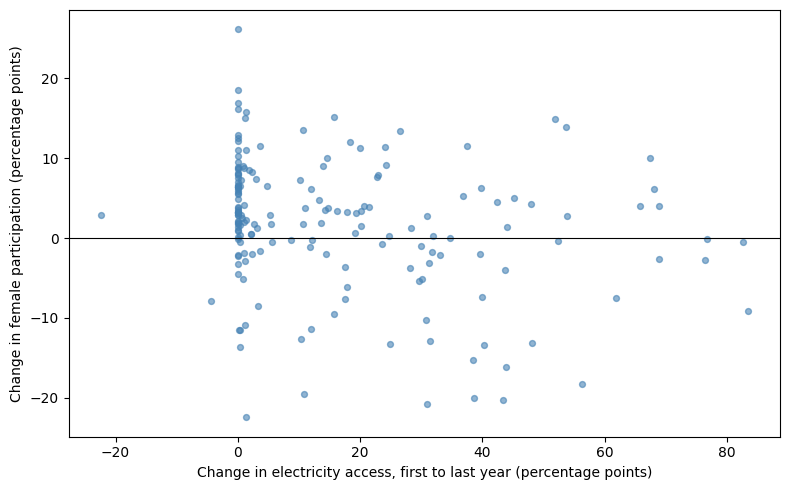

Countries with electricity gain > 10 points: 85 | median change in participation: 0.66
Countries with electricity gain <= 1 point: 69 I median change in participation: 3.83
Correlation of the two changes: -0.25


In [77]:
# Figure 3
first_last = est.sort_values("year").groupby("cc").agg(
    elec_first=("elec", "first"), elec_last=("elec", "last"),
    flfp_first=("flfp", "first"), flfp_last=("flfp", "last"))
first_last["d_elec"] = first_last["elec_last"] - first_last["elec_first"]
first_last["d_flfp"] = first_last["flfp_last"] - first_last["flfp_first"]

fig, ax = plt.subplots(figsize= (8, 5))
ax.scatter(first_last["d_elec"], first_last["d_flfp"], s = 18, alpha = 0.6, color = "steelblue")
ax.axhline(0, color = "black", linewidth = 0.8)
ax.set_xlabel("Change in electricity access, first to last year (percentage points)")
ax.set_ylabel("Change in female participation (percentage points)")
plt.tight_layout()
plt.savefig("outputs/fig3_within_country_changes.png", dpi = 200)
plt.show()

big = first_last["d_elec"] > 10
small = first_last["d_elec"] <= 1
print("Countries with electricity gain > 10 points:", big.sum(),
      "| median change in participation:", round(first_last.loc[big, "d_flfp"].median(), 2))
print("Countries with electricity gain <= 1 point:", small.sum(),
      "I median change in participation:", round(first_last.loc[small, "d_flfp"].median(), 2))
print("Correlation of the two changes:", round(first_last[["d_elec", "d_flfp"]].corr().iloc[0,1], 2))

- Figure 1: Female participation is spread out with most country years betweeen 40% and 65% and fwer between 10% and 35%. The skew is small (-0.42) so I use participation without a log. Electricity access is concentrated at the top, with 48.8% of country-years
having at least 99% access. This means most of the variation comes from smaller group of countries.

- Figure 2: Female participation is generally highest where electricity access is lowest. It averages 65.6% when access is below 20%, drops to around 45% between 60% and 95%, and rises slightly to 48.3% near full access. This shows the relationships is not linear. Each line represents one country over time, and many slope downward. At full electricity access, participation still ranges from 10% to 75%, showing that electricity alone does not explain female participation.

- Figure 3: Within countries, larger increases in electricity access are associated with smaller increases in female participation, but the relationship is weak (correlation -0.25). Countries with access increases above 10 points had a median participation change of +0.66 points, compared with + 3.83 points for countries where access changed by 1 point or less. Libya and Syria are the only countries where electricity access decreased, both during civil wars.

## Section 3: The Model (25 pts)

Fit a multivariate OLS model and report it in a formatted regression table (coefficients, standard errors, N, R-squared), not a `summary()` dump. Interpret at least two coefficients in full: magnitude, units, direction, precision. For every control, say whether it blocks a confounding path or adds precision, and what would make it a bad control (Chapter 10). OLS only: no difference-in-differences estimate.

In [78]:
m1 = smf.ols("flfp ~ elec + urban + C(cc) + C(year)", data=est).fit()
m2 = smf.ols("flfp ~ elec + urban + log_gdp + C(cc) + C(year)", data=est).fit()

table2 = summary_col(
    [m1, m2],
    model_names = ["(1) Without log GDP", "(2) With log GDP"],
    regressor_order = ["elec", "urban", "log_gdp"],
    drop_omitted = True,
    float_format = "%.3f",
    info_dict = {
        "N": lambda m: f"{int(m.nobs)}",
        "Country dummies": lambda m: "Yes",
        "Year dummies": lambda m: "Yes",
    }
)

table2.tables[0] = table2.tables[0].rename(index = {
    "elec": "Access to electricity (%)",
    "urban": "Urban population (%)",
    "log_gdp": "Log GDP per capita",
})

t = table2.tables[0]
bottom = ["N", "Country dummies", "Year dummies"]
keep = [i for i, name in enumerate(t.index) if name not in bottom]
table2.tables[0] = t.iloc[keep + [list(t.index).index(b) for b in bottom]]

print("Table 2. Dependent variable: female labor force participation (% of women 15+)")
print(table2)

table2.tables[0].to_csv("outputs/table2_regression.csv")


Table 2. Dependent variable: female labor force participation (% of women 15+)

                          (1) Without log GDP (2) With log GDP
--------------------------------------------------------------
Access to electricity (%) -0.083              -0.082          
                          (0.007)             (0.007)         
Urban population (%)      0.028               0.028           
                          (0.019)             (0.019)         
Log GDP per capita                            -0.347          
                                              (0.330)         
R-squared                 0.958               0.958           
R-squared Adj.            0.956               0.956           
N                         4389                4389            
Country dummies           Yes                 Yes             
Year dummies              Yes                 Yes             
Standard errors in parentheses.


In [79]:
m0 = smf.ols("flfp ~ C(cc) + C(year)", data=est).fit()
print(f"\nR-squared, country and year dummies only: {m0. rsquared:.3f}")
print(f"R-squared, Model 1: {m1.rsquared:.3f} | Model 2: {m2.rsquared:.3f}")


R-squared, country and year dummies only: 0.957
R-squared, Model 1: 0.958 | Model 2: 0.958


- Table 2 shows two OLS models of female labor force participation, both with country and year dummies. Model 1 does not include log GDP per capita, while Model 2 does. The electricity coefficients are almost identical (-0.083 and -0.082), meain adding income barely changes the result. Without GDP, the coefficient captures the overall association, including any part that works through higher income. With GDP, it measures the association while holding income constant. Since the results are nearly the same, the conclusion does not change.

- In Model 1, a 10-percentage-point increase in electricity access is associated with about 0.8 percentage points lower female participation within the same country, holding urban share and common year effects fixed. The 95% confidence interval is -0.097 to -0.069 per percentage point, showing a clear negative relationship. A 10 percentage point increase in urban share is associated with about 0.3 percentage points higher female participation, but the 95% confidence interval (-0.009 to 0.066 per point) includes zero, so the data cannot tell whether urbanization raises or lowers participation once country and year are held fixed. Although the R-squared is high (0.958), country and year dummies alone explain almost the same amount (0.957). This means most of the explained variation comes from country differences and year effects rather than electricity or urban share.

- Since the model includes country dummies, only countries where electricity access changed between 2000 and 2024 contribute to the electricity coefficient. Out of 177 countries, 136 has some change, while
87 changed by more than 10 percentages points. The other 41 had no change. mostly because they already had 100% acess. This means the coefficient mainly reflects countries where electricity access was changing during this periods, mostly lower income countries.

## Section 4: Diagnostics (20 pts)

Residuals against fitted values and against your main predictor; a constant-variance check, with robust standard errors if it fails; variance inflation factors, interpreted; at least one influential-observation check.

**Start only after Topic 14.** Write Sections 1 to 3 first; they do not depend on it.

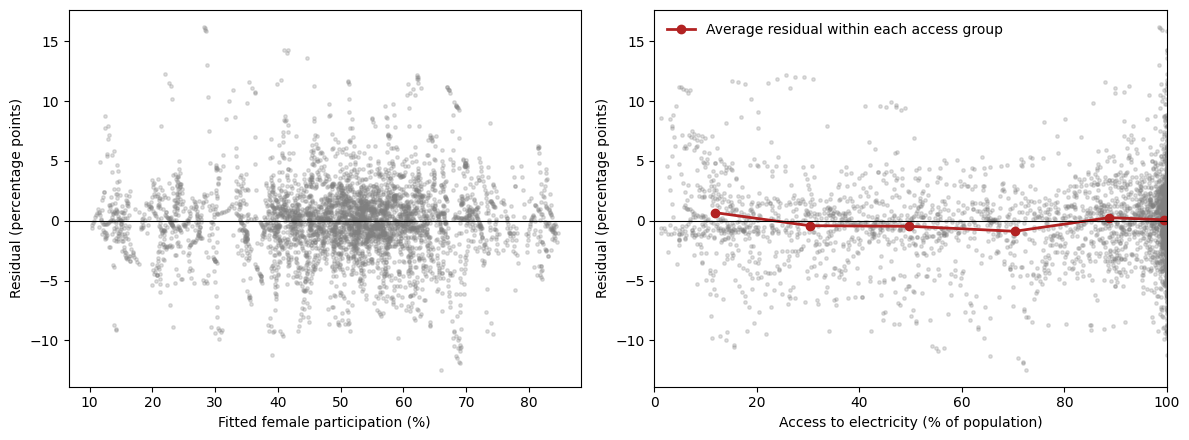

Average residual by electricity group:
elec
(0.0, 20.0]       0.68
(20.0, 40.0]     -0.41
(40.0, 60.0]     -0.46
(60.0, 80.0]     -0.88
(80.0, 95.0]      0.26
(95.0, 100.01]    0.08

Residual spread (std. dev.) by fifth of fitted values:
(10.349, 40.028]    3.34
(40.028, 49.0]      3.06
(49.0, 54.795]      2.67
(54.795, 61.641]    2.89
(61.641, 84.553]    3.67


In [80]:
resid = m1.resid
fitted = m1.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(fitted, resid, s = 6, alpha = 0.25, color = "gray")
axes[0].axhline(0, color = "black", linewidth = 0.8)
axes[0].set_xlabel("Fitted female participation (%)")
axes[0].set_ylabel("Residual (percentage points)")

axes[1].scatter(est["elec"], resid, s=6, alpha=0.25, color="gray")
bins = [0, 20, 40, 60, 80, 95, 100.01]
groups = pd.cut(est["elec"], bins)
rmeans = resid.groupby(groups, observed = True).mean()
emids = est["elec"].groupby(groups, observed = True).mean()
axes[1].plot(emids, rmeans, "o-", color = "firebrick", linewidth = 2,
             label="Average residual within each access group")
axes[1].axhline(0, color = "black", linewidth = 0.8)
axes[1].set_xlabel("Access to electricity (% of population)")
axes[1].set_ylabel("Residual (percentage points)")
axes[1].set_xlim(0, 100)
axes[1].legend(frameon = False)

plt.tight_layout ()
plt.savefig("outputs/fig4_residuals.png", dpi=200)
plt.show()

print("Average residual by electricity group:")
print(rmeans. round(2).to_string())
print("\nResidual spread (std. dev.) by fifth of fitted values:")
print(resid.groupby(pd.qcut(fitted, 5), observed = True).std().round(2).to_string())

In [81]:
lm, lm_p, fstat, f_p = het_breuschpagan(m1.resid, m1.model.exog)
print(f"Breusch-Pagan test: LM = {lm: 1f}, p-value = {lm_p:.4f}")

m1_robust = smf.ols("flfp ~ elec + urban + C(cc) + C(year)", data=est).fit(cov_type = "HC1")
m2_robust = smf.ols("flfp ~ elec + urban + log_gdp + C(cc) + C(year)", data=est). fit(cov_type = "HC1")

compare = pd.DataFrame({
    "Coef. (Model 1)": m1.params[["elec", "urban"]],
    "Usual SE": m1.bse[["elec", "urban"]],
    "Robust SE": m1_robust.bse[["elec", "urban"]],
}).round(3)
print("\nModel 1, usual vs robust standard errors:")
print(compare.to_string())
ci_r = m1_robust.conf_int().loc["elec"]
print(f"\nElectricity, robust 95% CI: [{ci_r[0]:.3f}, {ci_r[1]:.3f}]")

paper.update({f"bp_Im": round(lm, 1), "bp_p": lm_p,
              "elec_m1_robust_se": round(m1_robust.bse["elec"], 3)})

Breusch-Pagan test: LM =  2277.209677, p-value = 0.0000

Model 1, usual vs robust standard errors:
       Coef. (Model 1)  Usual SE  Robust SE
elec            -0.083     0.007      0.009
urban            0.028     0.019      0.021

Electricity, robust 95% CI: [-0.101, -0.065]


In [82]:
def vifs(model, names):
  x = model.model.exog
  cols = model.model.exog_names
  return pd.Series({n: variance_inflation_factor(x, cols.index(n)) for n in names}).round(1)

no_dummies = smf.ols("flfp ~ elec + urban + log_gdp", data=est).fit()

vif_table = pd.DataFrame({
    "VIF with country and year dummies (Model 2)": vifs(m2, ["elec", "urban", "log_gdp"]),
    "VIF without dummies": vifs(no_dummies, ["elec", "urban", "log_gdp"]),
})
print(vif_table.to_string())

         VIF with country and year dummies (Model 2)  VIF without dummies
elec                                            19.8                  2.7
urban                                           81.3                  2.6
log_gdp                                         64.5                  4.1


In [83]:
cooks = m1.get_influence().cooks_distance[0]
est["cooks"] = cooks
cutoff = 4 / len(est)

print(f"Largest Cook's distance: {cooks.max():.4f} (a common rule flags values above 1)")
print(f"Observations above 4/N = {cutoff:.5f}: {(cooks > cutoff).sum()}")
print("\nMost influential country-years:")
print(est.nlargest(8, "cooks")[["country", "year", "flfp", "elec", "cooks"]].round(4).to_string())

formula = "flfp ~ elec + urban + C(cc) + C(year)"
checks = {
    "Full sample": est,
    "Without obs. above 4/N": est[est["cooks"] <= cutoff],
    "Without Libya": est[est["cc"] != "LBY"],
}
rows = []
for name, data in checks.items ():
    m = smf.ols(formula, data = data).fit()
    rows.append({"Sample": name, "N": int(m.nobs),
                 "Electricity coef.": round (m.params["elec"], 3),
                 "SE": round (m. bse["elec"], 3)})
print("\nElectricity coefficient when influential observations are dropped:")
print(pd.DataFrame(rows).to_string(index = False))

est = est.drop(columns = "cooks")

Largest Cook's distance: 0.0063 (a common rule flags values above 1)
Observations above 4/N = 0.00091: 282

Most influential country-years:
                   country  year    flfp   elec   cooks
4750            Tajikistan  2000  44.394   98.5  0.0063
4751            Tajikistan  2001  44.397   98.6  0.0062
4752            Tajikistan  2002  44.400   99.0  0.0061
4753            Tajikistan  2003  44.404  100.0  0.0060
3099                 Malta  2024  55.894  100.0  0.0049
3097                 Malta  2022  55.307  100.0  0.0048
3098                 Malta  2023  55.525  100.0  0.0047
5120  United Arab Emirates  2020  58.180  100.0  0.0044

Electricity coefficient when influential observations are dropped:
                Sample    N  Electricity coef.    SE
           Full sample 4389             -0.083 0.007
Without obs. above 4/N 4107             -0.058 0.005
         Without Libya 4364             -0.085 0.007


- The residuals against fitted values show no strong pattern, but the spread is wider at both ends. The standard deviation is 3.34 and 3.67 points in the lowest and highest, compared with 2.67 in the middle. This suggests the variance is not constant. Against electricity access, the average residual also bends slightly, from +0.68 below 20% access to -0.88 between 60% and 80%. This is similar to the pattern in Figure 2, but the bend is small compared with the overall overall residual spread of about
3 points.

- The Breusch-Pagan test rejects constant variance LM = 2,277.2, p less than 0.0001, so I use robust standard errors. For electricity, the standard error increases from 0.007 and to 0.009, and the 95% confidence interval widens to -0.101 to -0.065 per percentage point. It is still below zero, so the conclusion does not change. For urban share, the standard error increases from 0.019 to 0.021, and and the confidence interval still includes zero.

- The VIFs are high with country and year dummies: 19.8 for electricity, 81.3 for urban share and 64.5 for log GDP. Without the dummies, all three are below 5. The high values come from the dummies because urban share and GDP change slowly within each country, leaving less variation to estimate their effects. This makes the estimates less precise and gives them wider confidenc intervals, but does not bias them. Electricity has a lower VIF because 87 countries changed access by more than 10 percentage points.

- No single observation is influential by the usual rule, since the largest Cook's distance is 0.0063, well below 1. However, 282 country years exceed the stricter cutoff of 4/N. Many come from Tajikistan between 2000 and 2003, where participation increases by almost the same small amount each year, suggesting modeled estimates rather than survey results. Dropping all 282 observations changes the electricity coefficient from -0.083 to -0.058, but it remains negative and precise. Dropping Libya barely changes it (-0.085). This shows that that the direction of the relationship is robust, but its size is somewhat sensitive, with a reasonable range of about -0.06 to -0.08 per percetnage point.

## Section 5: Threats and Conclusion (10 pts)

First the threats: what would have to be true for your main coefficient to be causal, is it, and if not, what your estimate is instead. Then the conclusion: what you found, how confident a reader should be, and what you would do with another month. Half a page. No new results, so there is no code cell here.

**Threat:** For the electricity coefficient to be causal, nothing else that changes within a country over time can affect both electricity access and female participation. Country dummies control for differences that stay fixed, and year dummies control for changes that affect all countries, but neither accounts for changes specific to one country. This is likely a problem because as countries gain electricity access, they also develop roads, expand education and move workers away from agriculture. Since many women in poorer countries work in agriculture, female participation could fall because of these changes rather than electricity itself.
My model does not control for this.

There are also three other limitations. First, many values are estimates rather than actual measurements. The ILO models participation for years without surveys, and the influential observations from Tajikistan (2000 - 2003 also appear to be modeled. Second, the relationship is not linear (Figures 2 and 4), meaning one coefficient averages a relationship that changes across different levels of electricity access. Third, residuals within countries tend to stay on the same side of zero over time, meaning observations are not fully independent and robust standard errors may still underestimate uncertainty. My sample also leaves out some conflict-affected countries because GDP data is missing.

Overall, my estimate should not be interpreted as a causal effect. It shows a conditional association: within the same country, years with higher electricity access are associated with lower female participation, holding urban share and common year effects fixed.

**Conclusion:** Within countries, a 10 percentage point increase in electricity access is associated with about 0.8 percentage points lower female labour force participation. The negative relationship stays similar with and without log GDP, with robust standard errors, and after dropping influential observations or Libya. However, the size is less certain, ranging from about -0.06 and to -0.08 per percentage point. The result mainly comes from the 87 countries, mostly low and lower-middle income, whowhose electricity access changed by more than 10 points. This suggests that countries gaining electricity did not see faster growth in women's measured participation between 2000 and 2024, but it does not mean that electricity reduces women's work.

If I had another month, I would add the share of employment in agriculture to test whether the shift away from farming helps explain the result. I would run the model with and without this variable because electricity could also affect it. I would also use only years with actual labour force surveys to see whether modeled values are driving the results. Finally, I would estimate separate relationships for countries with low and high electricity access to see whether the relationship changes instead of using one average coefficient.

## Appendix

The regression table, the diagnostics output and any extra figures. The appendix does not count toward the 6–8 page limit of the report.

In [84]:
compare.to_csv("outputs/tableA1_robust_se.csv")
vif_table.to_csv("outputs/tableA2_vif.csv")
influence_table = pd.DataFrame(rows)
influence_table.to_csv("outputs/tableA3_influential_obs.csv", index=False)

pd.Series(paper, name="value").to_csv("outputs/paper_numbers.csv")

print("Table A1. Model 1, usual vs robust standard errors")
print(compare.to_string(), "\n")
print("Table A2. Variance inflation factors")
print(vif_table.to_string(), "In")
print("Table A3. Electricity coefficient when influential observations are dropped")
print (influence_table.to_string(index = False), "\n")
print("Numbers used in the report:")
print(pd. Series(paper, name = "value").to_string())
print("\nFiles in outputs/:", sorted(os.listdir("outputs")))

Table A1. Model 1, usual vs robust standard errors
       Coef. (Model 1)  Usual SE  Robust SE
elec            -0.083     0.007      0.009
urban            0.028     0.019      0.021 

Table A2. Variance inflation factors
         VIF with country and year dummies (Model 2)  VIF without dummies
elec                                            19.8                  2.7
urban                                           81.3                  2.6
log_gdp                                         64.5                  4.1 In
Table A3. Electricity coefficient when influential observations are dropped
                Sample    N  Electricity coef.    SE
           Full sample 4389             -0.083 0.007
Without obs. above 4/N 4107             -0.058 0.005
         Without Libya 4364             -0.085 0.007 

Numbers used in the report:
rows_full            5425.000
countries_full        217.000
rows_est             4389.000
countries_est         177.000
missing_flfp          759.000
missing_ele

## Numbers my report quotes

Every number in your report, each with a name that says where it comes from. A number in the report that this cell does not print is unsupported, and is graded as if it were missing. Keep it the last code cell.

In [85]:
ci_m1 = m1.conf_int()
ci_rob = m1_robust.conf_int()
elec_range = est.groupby("cc")["elec"].agg(lambda s: s.max() - s.min())
sd_by_fifth = resid.groupby(pd.qcut(fitted, 5), observed=True).std()
tjk = est[(est["cc"] == "TJK") & (est["year"].between (2000, 2003))]["flfp"]
big10 = elec_range[elec_range > 10].index
low_lmic = meta.set_index("Country Code").loc[big10, "IncomeGroup"].isin(
    ["Low income", "Lower middle income"]).sum()

REPORT_NUMBERS = {
    "Section 1: rows in full panel": len(df),
    "Section 1: countries in full panel": df["cc"].nunique (),
    "Section 1: missing female participation": int(df["flfp"].isna().sum()),
    "Section 1: missing electricity access": int(df["elec"].isna().sum()),
    "Section 1: missing GDP per capita": int(df["gdp"].isna().sum()),
    "Section 1: missing urban share": int(df["urban"].isna().sum()),
    "Section 1: rows in final sample": len(est),
    "Section 1: countries in final sample": est["cc"].nunique(),

    "Section 2 (Fig 1): skew of female participation": round(est["flfp"].skew(), 2),
    "Section 2: skew of GDP per capita": round(est["gdp"].skew(), 2),
    "Section 2 (Fig 1): % of country-years with electricity >= 99%":round((est["elec"] >= 99).mean() * 100, 1),
    "Section 2 (Fig 2): mean participation, access below 20%": round (group_means["flfp_mean"].iloc[0], 1),
    "Section 2 (Fig 2): mean participation, access 60-80%": round(group_means["flfp_mean"].iloc[3], 1),
    "Section 2 (Fig 2): mean participation, access 80-95%": round(group_means["flfp_mean"].iloc[4], 1),
    "Section 2 (Fig 2): mean participation, access above 95%": round (group_means["flfp_mean"].iloc[5], 1),
    "Section 2 (Fig 3): countries with access gain > 10 points": int(big.sum()),
    "Section 2 (Fig 3): their median change in participation": round(first_last.loc[big, "d_flfp"].median(), 2),
    "Section 2 (Fig 3): countries with access change ‹= 1 point": int(small.sum()),
    "Section 2 (Fig 3): their median change in participation ": round(first_last.loc[small, "d_flfp"].median(), 2),
    "Section 2 (Fig 3): correlation of the two changes": round(first_last[["d_elec", "d_flfp"]].corr().iloc[0, 1], 2),
    "Section 2 (Fig 3): countries where access fell": int((first_last["d_elec"] < 0).sum()),

    "Section 3: electricity coef, Model 1": round(m1.params["elec"], 3),
    "Section 3: electricity SE, Model 1": round(m1.bse["elec"], 3),
    "Section 3: electricity 95% CI low, Model 1": round(ci_m1.loc["elec", 0], 3),
    "Section 3: electricity 95% CI high, Model 1": round(ci_m1.loc["elec", 1], 3),
    "Section 3: change in participation per 10-point rise in access": round (10 * m1.params["elec"], 2),
    "Section 3: electricity coef, Model 2": round(m2.params["elec"], 3),
    "Section 3: urban coef, Model 1": round (m1.params ["urban"], 3),
    "Section 3: urban SE, Model 1": round (m1.bse["urban"], 3),
    "Section 3: urban 95% CI low, Model 1": round(ci_m1.loc["urban", 0], 3),
    "Section 3: urban 95% CI high, Model 1": round(ci_m1. loc["urban", 1], 3),
    "Section 3: change in participation per 10-point rise in urban share": round(10 * m1.params["urban"], 2),
    "Section 3: log GDP coef, Model 2": round(m2.params["log_gdp"], 3),
    "Section 3: log GDP SE, Model 2": round(m2.bse["log_gdp"], 3),
    "Section 3: R-squared, Model 1": round(m1.rsquared, 3),
    "Section 3: R-squared, dummies only": round(m0.rsquared, 3),
    "Section 3: countries with any change in access": int((elec_range > 0).sum()),
    "Section 3: countries with change > 1 point": int((elec_range > 1).sum()),
    "Section 3: countries with change > 10 points": int((elec_range > 10).sum()),
    "Section 3: countries with no change (all at 100%)": int((elec_range == 0).sum()),
    "Section 3: of the > 10 point group, low or lower-middle income": int(low_lmic),

    "Section 4 (Fig 4): mean residual, access below 20%": round(rmeans.iloc[0], 2),
    "Section 4 (Fig 4): mean residual, access 60-80%": round(rmeans.iloc[3], 2),
    "Section 4 (Fig 4): residual SD, lowest fifth of fitted": round(sd_by_fifth.iloc[0], 2),
    "Section 4 (Fig 4): residual SD, middle fifth of fitted": round(sd_by_fifth.iloc[2], 2),
    "Section 4 (Fig 4): residual SD, highest fifth of fitted": round(sd_by_fifth.iloc[4], 2),
    "Section 4: Breusch-Pagan LM": round(lm, 1),
    "Section 4: Breusch-Pagan p-value": f"{lm_p:.2e}",
    "Section 4: electricity robust SE": round(m1_robust.bse["elec"], 3),
    "Section 4: electricity robust 95% CI low": round(ci_rob. loc["elec", 0], 3),
    "Section 4: electricity robust 95% CI high": round(ci_rob.loc["elec", 1], 3),
    "Section 4: urban robust SE": round(m1_robust.bse["urban"], 3),
    "Section 4: VIF electricity (with dummies)": vif_table.iloc[0,0],
    "Section 4: VIF urban (with dummies)": vif_table.iloc[1, 0],
    "Section 4: VIF log GDP (with dummies)": vif_table.iloc[2, 0],
    "Section 4: largest VIF without dummies": vif_table.iloc[:, 1].max(),
    "Section 4: largest Cook's distance": round(cooks.max (), 4),
    "Section 4: 4/N cutoff": round(cutoff, 5),
    "Section 4: observations above 4/N": int((cooks > cutoff).sum()),
    "Section 4: Tajikistan participation 2000": round(tjk.iloc[0], 3),
    "Section 4: Tajikistan participation 2003": round(tjk.iloc[-1], 3),
    "Section 4: electricity coef without obs, above 4/N": influence_table.iloc[1, 2],
    "Section 4: its SE": influence_table.iloc[1, 3],
    "Section 4: electricity coef without Libya": influence_table.iloc[2, 2],
}

for name, value in REPORT_NUMBERS.items():
    print(f"{name}: {value}")

print("\nTable 1")
print(summary.to_string())
print("\nTable 2")
print (table2)

Section 1: rows in full panel: 5425
Section 1: countries in full panel: 217
Section 1: missing female participation: 759
Section 1: missing electricity access: 75
Section 1: missing GDP per capita: 509
Section 1: missing urban share: 0
Section 1: rows in final sample: 4389
Section 1: countries in final sample: 177
Section 2 (Fig 1): skew of female participation: -0.42
Section 2: skew of GDP per capita: 1.9
Section 2 (Fig 1): % of country-years with electricity >= 99%: 48.8
Section 2 (Fig 2): mean participation, access below 20%: 65.6
Section 2 (Fig 2): mean participation, access 60-80%: 45.3
Section 2 (Fig 2): mean participation, access 80-95%: 45.3
Section 2 (Fig 2): mean participation, access above 95%: 48.3
Section 2 (Fig 3): countries with access gain > 10 points: 85
Section 2 (Fig 3): their median change in participation: 0.66
Section 2 (Fig 3): countries with access change ‹= 1 point: 69
Section 2 (Fig 3): their median change in participation : 3.83
Section 2 (Fig 3): correlation

## Checkpoints

In Colab, *File › Save a copy in GitHub* makes a commit each time you use it. Save at each checkpoint so the commit history shows it.

- [ ] **Mon 26 Oct:** your question and data source, posted in the Midterm checkpoint 1 discussion.
- [ ] **Mon 2 Nov:** your data loaded and your summary table, committed to your repository.
- [ ] **Fri 6 Nov:** a draft of your model, committed.
- [ ] **Mon 9 Nov, 11:59pm:** the project is due.

## Before you submit

- [ ] A Colab notebook with all your analysis, cleanly organised.
- [ ] A written report, 6 to 8 pages of text, uploaded as a PDF.
- [ ] A GitHub repository containing both, with a `README.md` you wrote yourself.
- [ ] **Question and data provenance (20):** A defensible measurable question; data described as a measurement product; missingness mechanism identified and defended; interpretable summary table
- [ ] **Descriptive evidence (20):** Two or more figures each making a stated point; captions state findings not variables; Chapter 3 standards met
- [ ] **Model and interpretation (25):** Properly formatted regression table; two coefficients interpreted in full including units and magnitude; every control justified by role
- [ ] **Diagnostics (20):** Residuals, heteroskedasticity, VIF and influence all run and interpreted; robust errors used where warranted
- [ ] **Threats and conclusion (10):** The causal claim assessed in plain terms; the estimand correctly labelled if not causal; conclusion adds no new results
- [ ] **Repository, checkpoints and reproducibility (5):** Public GitHub repo containing the notebook and the report; the two committed checkpoints visible in the commit history; data included or its download documented; a self-written README giving the question, the source, how to run it and the headline finding
- [ ] The Colab notebook is shared with *Anyone with the link*, and the link is in the Canvas submission box.
- [ ] Every number in the report is printed by the *Numbers my report quotes* cell.
- [ ] No AI anywhere: code, analysis, writing, editing, README.
- [ ] *File › Save a copy in GitHub*, path `Midterm Project/Econ_3916_Midterm.ipynb`.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.